# E-Commerce Customer Segmantation: Purchasing Behavior & Digital Engagement

## Step 1 _ Project Introduction 


### 1. Project Overview

Understanding customer behavior is essential for e-commerce businesses seeking to improve customer engagement, personalize marketing strategies, and make data-driven decisions.

In this project, I explore an e-commerce dataset to identify meaningful customer segments based on purchasing activity and digital engagement patterns.

I use K-Means Clustering, an unsupervised machine learning algorithm, to discover groups of customers with similar characteristics without relying on predefined customer labels.

### Business Problem

E-commerce customers differ in their purchasing habits, spending levels, and online engagement. Treating all customers as a single group may limit a business’s ability to understand these differences and develop targeted strategies.

Customer segmentation can help uncover behavioral patterns and provide insights that support more informed business decisions.

### Project Objectives

The main objectives of this analysis are to:

1. Explore and assess the quality of the e-commerce dataset.
2. Identify relevant purchasing and engagement features for customer segmentation.
3. Prepare and scale the selected features for distance-based clustering.
4. Apply K-Means clustering to identify groups of similar customers.
5. Evaluate the number and quality of clusters using the Elbow Method and Silhouette Score.
6. Examine the role of distance metrics in K-Means clustering.
7. Interpret the resulting customer segments and discuss potential business implications.

### Analytical Approach

I will begin with data exploration and preprocessing, followed by customer-level feature engineering and K-Means clustering.

I will use visualizations and clustering evaluation metrics to support my analytical decisions. Finally, I will interpret the identified segments, discuss their business relevance, and acknowledge the limitations of the analysis.

The goal is not only to identify clusters, but also to understand what makes each group distinct and how these differences might inform customer engagement and marketing strategies.

## Step 2_ Import Libraries & Load Dataset

### 2. Data Loading and Initial Exploration

In this section, I load the e-commerce dataset and examine its initial structure, including the number of observations, available features, and data types.

This initial assessment will help me understand the dataset before making decisions about data cleaning, feature selection, and customer-level aggregation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)

# Load the dataset
df = pd.read_csv("E_commerce.csv", low_memory=False)

# Preview the first five rows
df.head().T

,0,1,2,3,4
Customer ID,LS-001,IZ-002,EN-003,AN-004,ON-005
Customer Name,Lane Daniels,Alvarado Kriz,Moon Weien,Sanchez Bergman,Rowe Jackson
Segment,Consumer,Home Office,Consumer,Corporate,Corporate
City,Brisbane,Berlin,Porirua,Kabul,Townsville
State,Queensland,Berlin,Wellington,Kabul,Queensland
Country,Australia,Germany,New Zealand,Afghanistan,Australia
Region,Oceania,Central,Oceania,Central Asia,Oceania
Gender,Male,Male,Male,Male,Male
Age,22,32,21,22,28
Education,Associate Degree,Bachelor,High School,Bachelor,Associate Degree


## Step 3_ Initial Dataset Inspection

In [3]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Unique customers and orders
print("\nUnique customers:", df["Customer ID"].nunique())
print("Unique orders:", df["Order ID"].nunique())

Dataset shape: (51289, 27)

Column names:
['Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Region', 'Gender', 'Age', 'Education', 'Marital Status', 'Order ID', 'Order Date', 'Months', 'Ship Mode', 'Product Category', 'Product', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority', 'Browsing Time (min)', 'Like', 'Share', 'Add to Cart']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51289 entries, 0 to 51288
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer ID          51289 non-null  object 
 1   Customer Name        51289 non-null  object 
 2   Segment              51289 non-null  object 
 3   City                 51289 non-null  object 
 4   State                51289 non-null  object 
 5   Country              51289 non-null  object 
 6   Region               51215 non-null  object 
 7   Gender               51289 no

## Step 4 _ Data Quality Assessment 

### Data Quality Assessment

Before preparing the data for clustering, I examine missing values, duplicate records, and potential data type inconsistencies.

This step is important because data quality issues can affect feature engineering, distance calculations, and the reliability of customer segmentation.

I will first identify potential problems and then determine appropriate cleaning strategies based on the characteristics of the dataset.

In [4]:
# Check missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

display(missing_summary)

,Missing Count,Missing Percentage
Region,74,0.14
Quantity,1,0.00
Order Priority,2,0.00


In [5]:
# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Check repeated order IDs
print("Repeated Order IDs:", df["Order ID"].duplicated().sum())

# Check repeated customer IDs
print("Repeated Customer IDs:", df["Customer ID"].duplicated().sum())

Exact duplicate rows: 0
Repeated Order IDs: 16
Repeated Customer IDs: 50494


In [6]:
# Inspect values stored as text
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Cost"
]

for col in numeric_columns:
    print(f"\n{col}")
    print(df[col].head(10).tolist())


Sales
['$140.00 ', '$211.00 ', '$117.00 ', '$118.00 ', '$250.00 ', '$72.00 ', '$54.00 ', '$114.00 ', '$231.00 ', '$140.00 ']

Quantity
['2', '3', '5', '2', '1', '3', '1', '5', '5', '2']

Discount
['0.05', '0.03', '0.01', '0.05', '0.04', '0.04', '0.05', '0.02', '0.03', '0.02']

Profit
['$46.00 ', '$112.00 ', '$31.20 ', '$26.20 ', '$160.00 ', '$24.00 ', '$54.00 ', '$22.60 ', '$116.40 ', '$54.40 ']

Shipping Cost
['$4.60 ', '$11.20 ', '$3.10 ', '$2.60 ', '$16.00 ', '$2.40 ', '$5.40 ', '$2.30 ', '$11.60 ', '$5.40 ']


### Initial Data Quality Findings

The initial data quality assessment revealed a small number of missing values in three columns: Region (74), Quantity (1), and Order Priority (2). Overall, missing values represent a very small proportion of the dataset.

No exact duplicate rows were identified. However, 16 repeated Order IDs and 50,494 repeated Customer IDs were observed. Repeated customer identifiers are expected because individual customers may appear in multiple transaction records. Repeated order identifiers require further consideration but do not necessarily indicate duplicate transactions.

Several numerical variables, including Sales, Quantity, Discount, Profit, and Shipping Cost, were stored as text. These columns will need to be converted into appropriate numerical formats before further analysis.

Based on these findings, I will preserve the original observations and focus on correcting data types and evaluating missing values relevant to customer segmentation.

## Step 5_ Data Cleaning

### Data Cleaning and Preprocessing

To prepare the dataset for analysis, I will convert financial and numerical variables into appropriate data types and standardize the order date format.

I will preserve the original dataset and perform cleaning operations on a separate copy to maintain data integrity.

Rather than automatically removing observations with missing values, I will evaluate their relevance to the selected clustering features before deciding how to handle them.

In [7]:
# Create a working copy
df_clean = df.copy()

# Columns that should contain numeric values
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Cost"
]

# Remove currency symbols and convert to numeric
for col in numeric_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# Verify data types
print(df_clean[numeric_columns].dtypes)

# Check missing values after conversion
print("\nMissing values after conversion:")
print(df_clean[numeric_columns].isna().sum())

Sales            Float64
Quantity           Int64
Discount         Float64
Profit           Float64
Shipping Cost    Float64
dtype: object

Missing values after conversion:
Sales            1
Quantity         2
Discount         1
Profit           0
Shipping Cost    1
dtype: int64


In [8]:
# Convert Order Date to datetime
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)

# Verify date conversion
print("Order Date type:", df_clean["Order Date"].dtype)

print("\nDate range:")
print("Earliest:", df_clean["Order Date"].min())
print("Latest:", df_clean["Order Date"].max())

print("\nInvalid dates:")
print(df_clean["Order Date"].isna().sum())

Order Date type: datetime64[ns]

Date range:
Earliest: 2022-01-13 00:00:00
Latest: 2024-12-31 00:00:00

Invalid dates:
0


### Data Cleaning Results

I successfully converted the financial and numerical columns into appropriate numeric data types. Following the conversion, I identified a small number of missing or non-convertible values in Sales (1), Quantity (2), Discount (1), and Shipping Cost (1). Profit contained no missing values.

I also converted Order Date into datetime format. The dataset covers transactions from January 13, 2022, through December 31, 2024, with no invalid dates identified.

These results confirm that the main data types are now suitable for further analysis. Before customer-level aggregation, I will examine the remaining missing values and determine how to handle them without unnecessarily removing valid observations.

## Step 6_ Inspect Missing and Invalid Values

### 6.1 Investigating Missing and Invalid Values

Although the dataset contains relatively few missing values, I want to inspect the affected observations before applying any cleaning strategy.

This will help me determine whether the missing values can be handled appropriately while preserving useful customer information.

In [9]:
# Identify rows with missing numeric values
missing_numeric = df_clean[
    df_clean[numeric_columns].isna().any(axis=1)
]

# Display affected observations
display(
    missing_numeric[
        ["Customer ID", "Order ID"] + numeric_columns
    ]
)

# Compare original values before conversion
print("Original values in affected rows:")
display(
    df.loc[missing_numeric.index,
           ["Customer ID", "Order ID"] + numeric_columns]
)

,Customer ID,Order ID,Sales,Quantity,Discount,Profit,Shipping Cost
95,ON-0096,AU-2024-96,72.0,<NA>,0.01,36.0,3.6
210,EE-0034,AU-2024-212,250.0,5,<NA>,132.5,13.3
320,CH-00322,AU-2024-322,54.0,<NA>,0.02,54.0,5.4
534,ON-00536,AU-2024-536,250.0,4,0.02,150.0,<NA>
792,RE-00197,AU-2024-794,<NA>,3,0.01,124.7,12.5


Original values in affected rows:


,Customer ID,Order ID,Sales,Quantity,Discount,Profit,Shipping Cost
95,ON-0096,AU-2024-96,$72.00,NaN,0.01,$36.00,$3.60
210,EE-0034,AU-2024-212,$250.00,5,xxx,$132.50,$13.30
320,CH-00322,AU-2024-322,$54.00,abc,0.02,$54.00,$5.40
534,ON-00536,AU-2024-536,$250.00,4,0.02,$150.00,test
792,RE-00197,AU-2024-794,0.xf,3,0.01,$124.70,$12.50


### Handling Missing and Invalid Numeric Values

After examining the affected observations, I identified five records containing missing or invalid numeric values. These issues included missing quantities and non-numeric entries in Sales, Quantity, Discount, and Shipping Cost.

Because these five records represent approximately 0.01% of the dataset, I decided to exclude them from the analysis rather than impute potentially inaccurate transaction values.

This approach helps preserve the reliability of the purchasing metrics used for customer-level feature engineering. However, removing these records also means that the corresponding transaction information will not contribute to the final customer profiles.

Missing values in other columns will be evaluated separately based on their relevance to the clustering analysis.

## Step 7_Remove Invalid Numeric Record

In [10]:
# Remove records with missing or invalid numeric values
rows_before = len(df_clean)

df_clean = df_clean.dropna(
    subset=numeric_columns
).copy()

rows_after = len(df_clean)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nRemaining missing numeric values:")
print(df_clean[numeric_columns].isna().sum())

Rows before cleaning: 51289
Rows after cleaning: 51284
Rows removed: 5

Remaining missing numeric values:
Sales            0
Quantity         0
Discount         0
Profit           0
Shipping Cost    0
dtype: int64


### Data Cleaning Summary

After removing five records with missing or invalid numeric values, the cleaned dataset contains 51,284 observations.

All five numerical variables examined—Sales, Quantity, Discount, Profit, and Shipping Cost—now contain valid, non-missing numeric values.

Only approximately 0.01% of the original observations were excluded. I retained the remaining records for exploratory analysis and customer-level feature engineering.

## Step 8_ Exploratory Data Analysis (EDA)


### Exploratory Data Analysis (EDA)

Before applying K-Means clustering, I explore the distributions and characteristics of the numerical variables in the cleaned dataset.

The goal is to understand purchasing behavior, identify potential outliers, and assess whether the features may require additional preprocessing before clustering.

I will begin with descriptive statistics and then use visualizations to investigate the most relevant purchasing and engagement variables.

In [11]:
# Summary statistics for numerical variables
eda_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Cost",
    "Browsing Time (min)",
    "Age"
]

display(
    df_clean[eda_columns].describe().round(2)
)

,Sales,Quantity,Discount,Profit,Shipping Cost,Browsing Time (min),Age
count,51284.0,51284.0,51284.0,51284.0,51284.0,51284.00,51284.00
mean,156.43,3.0,0.03,72.72,7.27,17.28,31.32
std,65.78,1.41,0.01,49.1,4.91,9.67,11.90
min,33.0,1.0,0.01,0.5,0.1,1.00,18.00
25%,109.0,2.0,0.02,25.7,2.6,9.30,22.00
50%,159.0,3.0,0.03,67.0,6.7,16.50,28.00
75%,218.0,4.0,0.04,120.6,12.1,24.60,37.00
max,250.0,5.0,0.05,167.5,16.8,40.00,70.00


### Interpretation of Descriptive Statistics

The descriptive statistics provide an initial overview of purchasing activity and customer engagement in the cleaned dataset.

The average sales amount is 156.43 , with a median of 159 , while the average quantity is approximately three items per record. Profit averages 72.72 ,  slightly above its median of  67, suggesting possible right-skewness that requires further visual examination.

Browsing time ranges from 1 to 40 minutes, with an average of 17.28 minutes. This variation may help distinguish different levels of digital engagement.

Customer ages range from 18 to 70 years, with a mean of 31.32 and a median of 28.

I also observe substantial differences in the numerical scales of the variables. For example, Sales ranges from $33 to $250, while Discount ranges from 0.01 to 0.05. This highlights the importance of feature scaling before applying distance-based clustering.

These statistics describe the original transaction-level observations. Customer-level features will be constructed separately before applying K-Means.

## Step 9_ Visualizing Numerical Distributions

### Distribution of Purchasing and Engagement Variables

To better understand the dataset, I examine the distributions of Sales, Profit, and Browsing Time.

Histograms help reveal the concentration, spread, and potential skewness of numerical variables. These patterns are useful for identifying unusual observations and informing later preprocessing decisions.

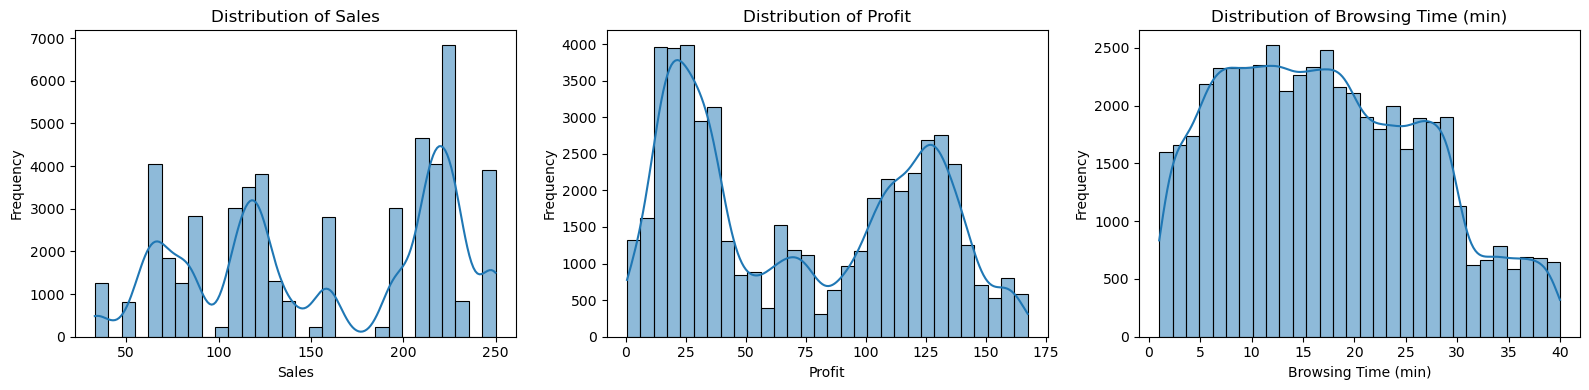

In [12]:
# Visualize key numerical distributions
features = ["Sales", "Profit", "Browsing Time (min)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, features):
    sns.histplot(
        data=df_clean,
        x=feature,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("numerical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation of Numerical Distributions

The histograms reveal several interesting patterns in purchasing activity and customer engagement.

Sales: The distribution is multimodal, with noticeable concentrations around specific transaction values. This suggests that sales amounts are not evenly distributed across observations.

Profit: The profit distribution also shows multiple concentrations, including lower-profit and higher-profit transactions. These patterns may reflect differences in purchasing activity or product characteristics.

Browsing Time: Most observations are concentrated between approximately 5 and 30 minutes, with fewer observations at longer browsing durations. The distribution appears more continuous than those of Sales and Profit.

Overall, these visualizations reveal variation in transaction values and browsing behavior. However, transaction-level patterns do not necessarily represent distinct customer segments.

The next step is to construct customer-level features and investigate whether meaningful behavioral differences exist between customers.

## Step 10 _ Customer-Level Feature Engineering

### Customer-Level Feature Engineering

The original dataset contains multiple transaction records for individual customers. Since the objective of this project is customer segmentation rather than transaction segmentation, I will aggregate the data at the customer level.

I will construct customer profiles using purchasing activity and digital engagement metrics, including total sales, order frequency, average order value, browsing time, and interaction rates.

These features will help describe customer behavior and support the identification of potentially meaningful customer segments.

Before clustering, I will evaluate feature distributions, relationships, and scaling requirements to select an appropriate set of variables.

In [13]:
# Aggregate transaction data at the customer level
customer_df = df_clean.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Avg_Browsing_Time=("Browsing Time (min)", "mean"),
    Like_Rate=("Like", "mean"),
    Share_Rate=("Share", "mean"),
    Add_to_Cart_Rate=("Add to Cart", "mean")
).reset_index()

# Calculate average order value
customer_df["Avg_Order_Value"] = (
    customer_df["Total_Sales"] / customer_df["Total_Orders"]
)

# Check the customer-level dataset
print("Customer-level dataset shape:", customer_df.shape)
print("Unique customers:", customer_df["Customer ID"].nunique())

display(customer_df.head())

Customer-level dataset shape: (795, 9)
Unique customers: 795


,Customer ID,Total_Sales,Total_Orders,Total_Quantity,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate,Avg_Order_Value
0,AB-00363,8960.0,58,178,22.746552,0.672414,0.672414,0.793103,154.482759
1,AB-00421,7840.0,45,146,12.937778,0.377778,0.288889,0.511111,174.222222
2,AB-004408,7747.0,49,157,20.526531,0.734694,0.734694,0.836735,158.102041
3,AH-00722,8070.0,52,163,22.501923,0.730769,0.634615,0.826923,155.192308
4,AK-00157,9489.0,62,179,20.422581,0.774194,0.709677,0.854839,153.048387


### Customer-Level Aggregation Results

After aggregating the transaction-level data, I obtained a customer-level dataset containing 795 unique customers and eight numerical features, along with Customer ID.

Each row now represents an individual customer rather than a transaction record.

The engineered features summarize purchasing activity, order frequency, browsing behavior, and engagement rates. This transformation allows me to examine behavioral differences between customers and prepare the data for K-Means clustering.

Before selecting the final clustering features, I will examine their distributions and correlations to identify potentially redundant variables and determine appropriate preprocessing steps.

## Step 11_ Exploring Relationships Between Customer Features

### Correlation Analysis of Customer Features

Before applying K-Means clustering, I examine the relationships among the engineered customer-level features.

A correlation heatmap helps identify strongly related variables, potential redundancy, and meaningful associations between purchasing activity and digital engagement.

Since K-Means relies on distances between observations, including several highly correlated features may unintentionally increase the influence of certain behavioral dimensions.

I will use these findings to guide feature selection before scaling and clustering.

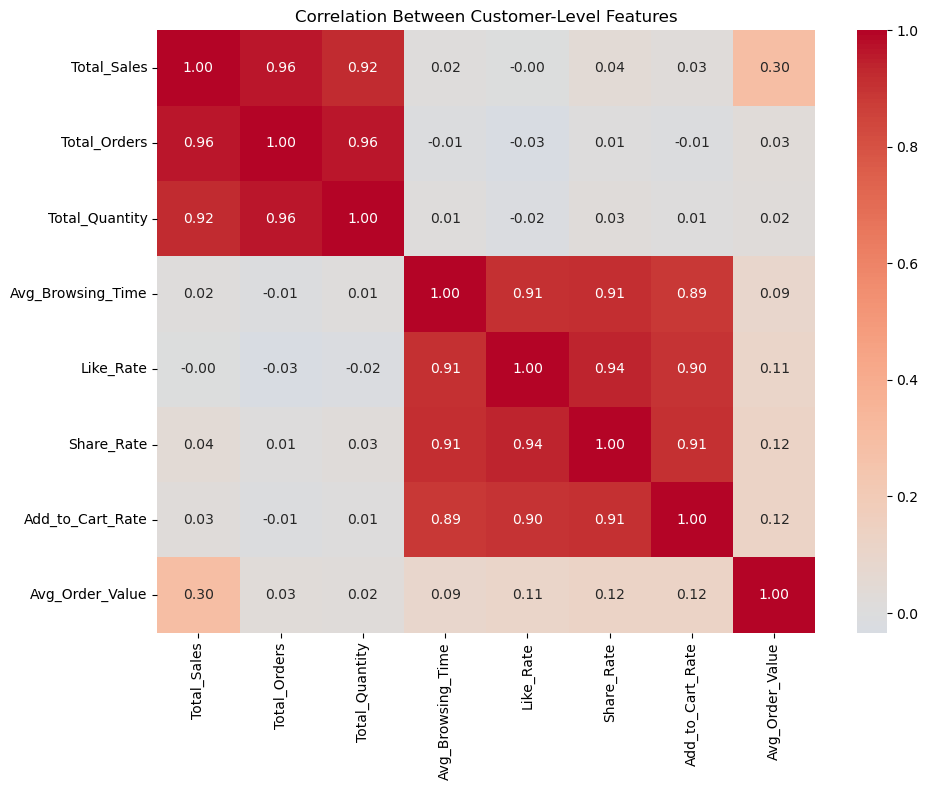

In [14]:
# Select numerical customer features
customer_features = customer_df.drop(columns=["Customer ID"])

# Calculate correlation matrix
corr_matrix = customer_features.corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Customer-Level Features")
plt.tight_layout()

plt.savefig(
    "customer_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation of Customer Feature Correlations

The correlation heatmap reveals two groups of strongly related customer features.

Purchasing Activity: Total Sales, Total Orders, and Total Quantity exhibit strong positive correlations, ranging from 0.92 to 0.96. These variables capture closely related aspects of purchasing activity, suggesting that including all three in K-Means could overemphasize this behavioral dimension.

Digital Engagement: Average Browsing Time, Like Rate, Share Rate, and Add-to-Cart Rate are also strongly correlated, with coefficients ranging approximately from 0.89 to 0.94. This suggests that these variables may reflect a shared dimension of customer engagement.

Purchasing vs. Engagement: Correlations between purchasing activity and engagement metrics are generally close to zero. This indicates that purchasing volume and digital engagement represent relatively distinct behavioral dimensions in this dataset.

Average Order Value: This feature has a moderate-to-weak positive correlation with Total Sales (0.30) and relatively weak correlations with most other variables, suggesting that it may provide additional information about customer purchasing behavior.

Overall, these findings highlight the importance of selecting a balanced set of clustering features rather than including every available variable. The final feature selection will aim to represent purchasing activity, transaction value, and digital engagement without unnecessarily emphasizing highly correlated measures.

## Step 12_ Selecting Features for K_Means

### Feature Selection for K-Means Clustering

Based on the correlation analysis, I selected an initial set of four features representing different aspects of customer behavior:

* Total Orders: Customer purchasing frequency.
* Average Order Value: Average monetary value per order.
* Average Browsing Time: Digital browsing engagement.
* Add-to-Cart Rate: Frequency of recorded add-to-cart interactions.

I excluded Total Sales and Total Quantity from the initial feature set because they are strongly correlated with Total Orders. Similarly, I excluded Like Rate and Share Rate to reduce redundancy among engagement variables.

Although Average Browsing Time and Add-to-Cart Rate are also strongly correlated, I will initially retain both to examine whether they provide useful complementary information.

This feature selection is an initial modeling decision rather than a final conclusion. I will evaluate clustering quality and interpretability before determining the most appropriate feature set.

In [15]:
# Select features for initial K-Means analysis
selected_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Avg_Browsing_Time",
    "Add_to_Cart_Rate"
]

X = customer_df[selected_features].copy()

print("Selected features:")
print(X.columns.tolist())

print("\nDataset shape:")
print(X.shape)

print("\nMissing values:")
print(X.isna().sum())

display(X.describe().round(2))

Selected features:
['Total_Orders', 'Avg_Order_Value', 'Avg_Browsing_Time', 'Add_to_Cart_Rate']

Dataset shape:
(795, 4)

Missing values:
Total_Orders         0
Avg_Order_Value      0
Avg_Browsing_Time    0
Add_to_Cart_Rate     0
dtype: int64


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Add_to_Cart_Rate
count,795.00,795.0,795.00,795.00
mean,64.51,156.37,17.29,0.67
std,13.43,9.46,4.18,0.14
min,29.00,124.75,10.74,0.33
25%,55.00,150.01,13.16,0.54
50%,64.00,156.29,18.70,0.68
75%,74.00,162.93,21.24,0.79
max,108.00,184.75,25.29,0.96


### Initial Feature Selection Results

The selected dataset contains 795 customers and four numerical features, with no missing values.

The descriptive statistics reveal substantial differences in feature scales. For example, Total Orders ranges from 29 to 108, while Add-to-Cart Rate ranges from approximately 0.33 to 0.96.

These features represent purchasing frequency, average transaction value, browsing activity, and add-to-cart engagement.

Because K-Means relies on distance calculations, I will standardize the selected features before clustering to prevent differences in numerical scale from disproportionately influencing the results.

## Step 13_Feature Scaling Using StandardScaler

### Feature Scaling

K-Means clustering is a distance-based algorithm, making feature scaling an essential preprocessing step when variables have different numerical ranges.

I use StandardScaler to transform each selected feature to have a mean of approximately zero and a standard deviation of one.

This transformation reduces the influence of differences in measurement units and allows the clustering algorithm to compare customer characteristics on a more balanced numerical scale.

Standardization does not eliminate correlations between features, so highly related variables may still influence clustering results.

In [16]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Standardize selected features
X_scaled = scaler.fit_transform(X)

# Convert scaled data to a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=selected_features,
    index=X.index
)

# Verify scaling results
print("Scaled dataset shape:", X_scaled_df.shape)

print("\nMean after scaling:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation after scaling:")
print(X_scaled_df.std(ddof=0).round(2))

display(X_scaled_df.head())

Scaled dataset shape: (795, 4)

Mean after scaling:
Total_Orders         0.0
Avg_Order_Value     -0.0
Avg_Browsing_Time   -0.0
Add_to_Cart_Rate    -0.0
dtype: float64

Standard deviation after scaling:
Total_Orders         1.0
Avg_Order_Value      1.0
Avg_Browsing_Time    1.0
Add_to_Cart_Rate     1.0
dtype: float64


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Add_to_Cart_Rate
0,-0.484758,-0.199766,1.306392,0.914390
1,-1.453055,1.889240,-1.039886,-1.131262
2,-1.155118,0.183259,0.775359,1.230903
3,-0.931664,-0.124675,1.247877,1.159727
4,-0.186820,-0.351564,0.750494,1.362235


## Step 14_ Finding the Optimal Number of Clusters Using the Elbow Method

### Determining the Number of Clusters

#### Elbow Method

Before applying the final K-Means model, I evaluate different numbers of clusters using the Elbow Method.

The Elbow Method measures within-cluster variation through inertia, which represents the sum of squared distances between observations and their assigned cluster centers.

As the number of clusters increases, inertia generally decreases. However, adding more clusters does not always provide meaningful improvements.

I examine the Elbow Curve to identify a potential point of diminishing returns. I will also use Silhouette Scores to support the selection of an appropriate number of clusters.

C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

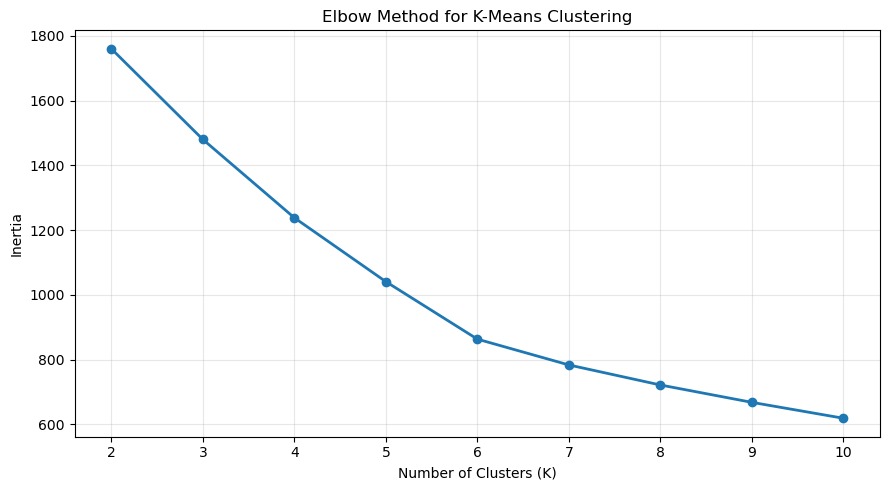

In [17]:
# Import K-Means
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled_df)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Elbow Method Interpretation

The Elbow Curve shows a consistent reduction in inertia as the number of clusters increases.

The reduction becomes noticeably smaller after approximately six clusters, suggesting that K=6 may represent a reasonable balance between cluster compactness and model complexity.

However, the curve does not display a sharply defined elbow, making it difficult to determine the optimal number of clusters using inertia alone.

Therefore, I will evaluate Silhouette Scores across different K values before selecting the final clustering model.

## Step 15_ Silhouette Score

### Silhouette Score Evaluation

Since the Elbow Method did not reveal a sharply defined optimal number of clusters, I use the Silhouette Score as an additional evaluation metric.

The Silhouette Score measures how closely observations are grouped within their assigned clusters compared with neighboring clusters.

Higher scores generally indicate more compact and better-separated clusters.

I compare Silhouette Scores for K values from 2 to 10 to identify promising clustering solutions and support the final model selection.

C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

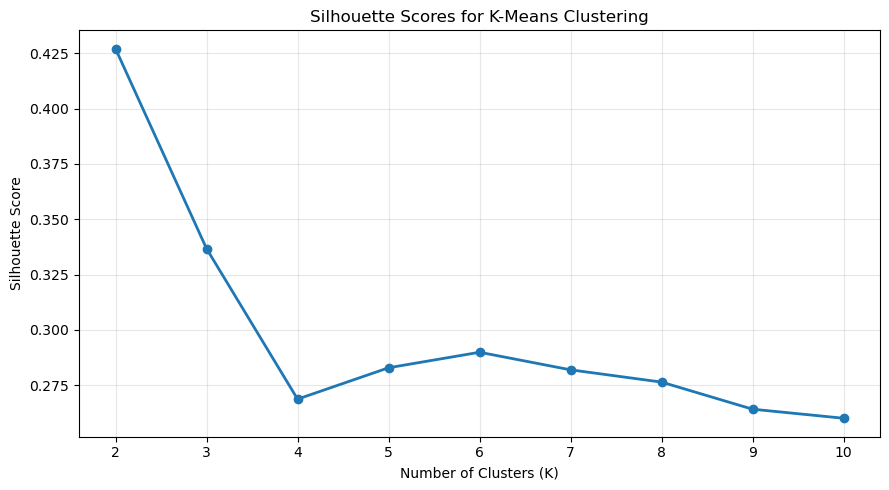

Best K based on Silhouette Score: 2
Highest Silhouette Score: 0.427


In [18]:
from sklearn.metrics import silhouette_score

# Evaluate Silhouette Scores for different K values
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled_df)

    score = silhouette_score(X_scaled_df, cluster_labels)
    silhouette_scores.append(score)

# Plot Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    linewidth=2
)

plt.title("Silhouette Scores for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display the best K
best_k = list(range(2, 11))[silhouette_scores.index(max(silhouette_scores))]

print("Best K based on Silhouette Score:", best_k)
print("Highest Silhouette Score:", round(max(silhouette_scores), 3))

### Silhouette Score Interpretation and Cluster Selection

The Silhouette analysis identifies K=2 as the strongest solution, achieving the highest average Silhouette Score of 0.427.

Although the Elbow Method suggested a potential turning point around K=6, the Silhouette Scores indicate that dividing customers into two clusters produces better separation and cohesion.

Based on these results, I select K=2 as the initial clustering solution. This choice balances clustering quality with interpretability.

In the next step, I will examine the characteristics and sizes of the resulting clusters to determine whether they represent meaningful customer segments.

The final interpretation will also consider that the selected behavioral features are correlated and that clustering patterns do not establish causal relationships.

## Step 16_ Building the Final K_Means Model

In [19]:
# Build the final K-Means model
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
customer_df["Cluster"] = final_kmeans.fit_predict(X_scaled_df)

# Check the number of customers in each cluster
cluster_counts = (
    customer_df["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_percentages = (
    customer_df["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

cluster_summary = pd.DataFrame({
    "Customers": cluster_counts,
    "Percentage": cluster_percentages.round(2)
})

print("Customer Distribution Across Clusters:")
display(cluster_summary)

print("\nFinal Silhouette Score:")
print(round(
    silhouette_score(X_scaled_df, customer_df["Cluster"]),
    3
))

Customer Distribution Across Clusters:


C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,Customers,Percentage
Cluster,,
0,405,50.94
1,390,49.06



Final Silhouette Score:
0.427


## Step 17_ Customer Cluster Profiling

### Customer Cluster Profiling

After selecting K=2 and fitting the final K-Means model, I examine the characteristics of each customer segment.

The purpose of this analysis is to understand how the identified clusters differ in purchasing activity, average order value, browsing behavior, and add-to-cart engagement.

I compare the average values of the four clustering features in their original units to make the results easier to interpret.

This analysis will help determine whether the clusters represent meaningful customer behavior patterns and provide a foundation for potential business recommendations.

In [20]:
# Compare customer characteristics across clusters
profile_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Avg_Browsing_Time",
    "Add_to_Cart_Rate"
]

cluster_profile = (
    customer_df.groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

print("Average Customer Characteristics by Cluster:")
display(cluster_profile)

Average Customer Characteristics by Cluster:


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Add_to_Cart_Rate
Cluster,,,,
0,64.47,157.45,21.25,0.79
1,64.55,155.25,13.17,0.54


## Step 18_ Revisiting the Clustering Strategy

### Revisiting the Clustering Strategy

The initial K-Means clustering analysis identified two customer segments with different engagement patterns. Cluster 0 showed higher average browsing time and add-to-cart rates, while Cluster 1 demonstrated lower engagement levels.

However, both clusters had nearly identical average order counts and relatively similar average order values. This suggests that the initial clustering approach primarily captured differences in customer engagement rather than differences in purchasing value.

Since the main business objective of this project is to identify high-value customers and understand revenue-generating behavior, I decided to extend the analysis using two complementary clustering approaches:

#### 1. Engagement-Based Clustering

This approach will focus on customer interactions, including browsing time, likes, shares, and add-to-cart behavior.

#### 2. Revenue-Based Clustering

This approach will focus on purchasing activity and customer value, using transaction-related features to identify economically meaningful customer segments.

By comparing these two approaches, I aim to investigate whether customers with higher engagement also generate greater purchasing value.

This revised strategy builds on the initial findings rather than replacing the previous analysis. It also provides a more comprehensive understanding of customer behavior while maintaining a clear business focus.

## Step 19_ Feature Selection for Engagement-Based Clustering

### Engagement-Based Clustering: Feature Selection

For the engagement-based clustering model, I selected four customer-level behavioral features: average browsing time, like rate, share rate, and add-to-cart rate.

These features represent different aspects of customer interaction with the e-commerce platform.

The previous correlation analysis showed strong relationships among several engagement variables. Therefore, I will examine their correlations before fitting the model to assess potential redundancy and avoid overemphasizing closely related behaviors.

The objective is to identify meaningful customer engagement segments while keeping the clustering approach interpretable.

Engagement dataset shape: (795, 4)

Missing values:
Avg_Browsing_Time    0
Like_Rate            0
Share_Rate           0
Add_to_Cart_Rate     0
dtype: int64

Engagement feature correlations:


,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Avg_Browsing_Time,1.000,0.911,0.911,0.886
Like_Rate,0.911,1.000,0.936,0.895
Share_Rate,0.911,0.936,1.000,0.910
Add_to_Cart_Rate,0.886,0.895,0.910,1.000


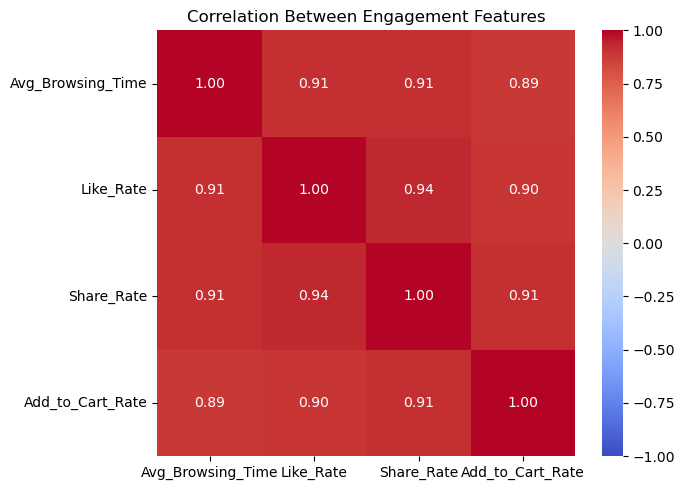

In [21]:
# Step 19: Select engagement-related features

engagement_features = [
    "Avg_Browsing_Time",
    "Like_Rate",
    "Share_Rate",
    "Add_to_Cart_Rate"
]

X_engagement = customer_df[engagement_features].copy()

# Check feature availability and missing values
print("Engagement dataset shape:", X_engagement.shape)

print("\nMissing values:")
print(X_engagement.isna().sum())

# Examine correlations between engagement features
engagement_corr = X_engagement.corr()

print("\nEngagement feature correlations:")
display(engagement_corr.round(3))

# Visualize correlations
plt.figure(figsize=(7, 5))

sns.heatmap(
    engagement_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Engagement Features")
plt.tight_layout()
plt.show()

### Engagement Feature Correlation Analysis

The correlation analysis reveals strong positive relationships among all four engagement features, with correlation coefficients ranging from 0.886 to 0.936.

The strongest relationship is observed between Like Rate and Share Rate (r = 0.936), suggesting that these engagement behaviors tend to occur together.

Although the features are highly correlated, I decided to retain all four because they represent different types of customer interactions: browsing, liking, sharing, and adding products to the cart.

However, these correlations indicate substantial overlap among the features. Therefore, the resulting clusters will be interpreted primarily as overall engagement segments rather than completely independent behavioral dimensions.

## Step 20_ Scaling Engagement Features

### Feature Standardization

Before applying K-Means clustering, I standardized the selected engagement features using StandardScaler.

Since K-Means relies on Euclidean distances, standardization prevents features with larger numerical scales from dominating the clustering process.

Each feature is transformed to have approximately zero mean and unit variance, allowing the model to compare customer engagement patterns on a consistent scale.

In [22]:
# Step 20: Standardize engagement features

from sklearn.preprocessing import StandardScaler

engagement_scaler = StandardScaler()

X_engagement_scaled = engagement_scaler.fit_transform(
    X_engagement
)

# Convert scaled values to a DataFrame
X_engagement_scaled_df = pd.DataFrame(
    X_engagement_scaled,
    columns=engagement_features,
    index=X_engagement.index
)

# Verify standardization
print("Scaled dataset shape:", X_engagement_scaled_df.shape)

print("\nMean after scaling:")
print(X_engagement_scaled_df.mean().round(2))

print("\nStandard deviation after scaling:")
print(X_engagement_scaled_df.std(ddof=0).round(2))

display(X_engagement_scaled_df.head())

Scaled dataset shape: (795, 4)

Mean after scaling:
Avg_Browsing_Time   -0.0
Like_Rate           -0.0
Share_Rate          -0.0
Add_to_Cart_Rate    -0.0
dtype: float64

Standard deviation after scaling:
Avg_Browsing_Time    1.0
Like_Rate            1.0
Share_Rate           1.0
Add_to_Cart_Rate     1.0
dtype: float64


,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
0,1.306392,0.627392,0.909432,0.914390
1,-1.039886,-1.151829,-1.174059,-1.131262
2,0.775359,1.003484,1.247767,1.230903
3,1.247877,0.979784,0.704093,1.159727
4,0.750494,1.242011,1.111865,1.362235


## Step 21_ Selecting the Optimal Number of Engagement Clusters

### Determining the Optimal Number of Engagement Clusters

To identify an appropriate number of customer engagement segments, I evaluated K-Means clustering using both the Elbow Method and Silhouette Score.

The Elbow Method measures how within-cluster variation decreases as the number of clusters increases, while the Silhouette Score evaluates cluster cohesion and separation.

I visualized both metrics side by side to compare their results and select a cluster count that balances statistical performance with business interpretability.

C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

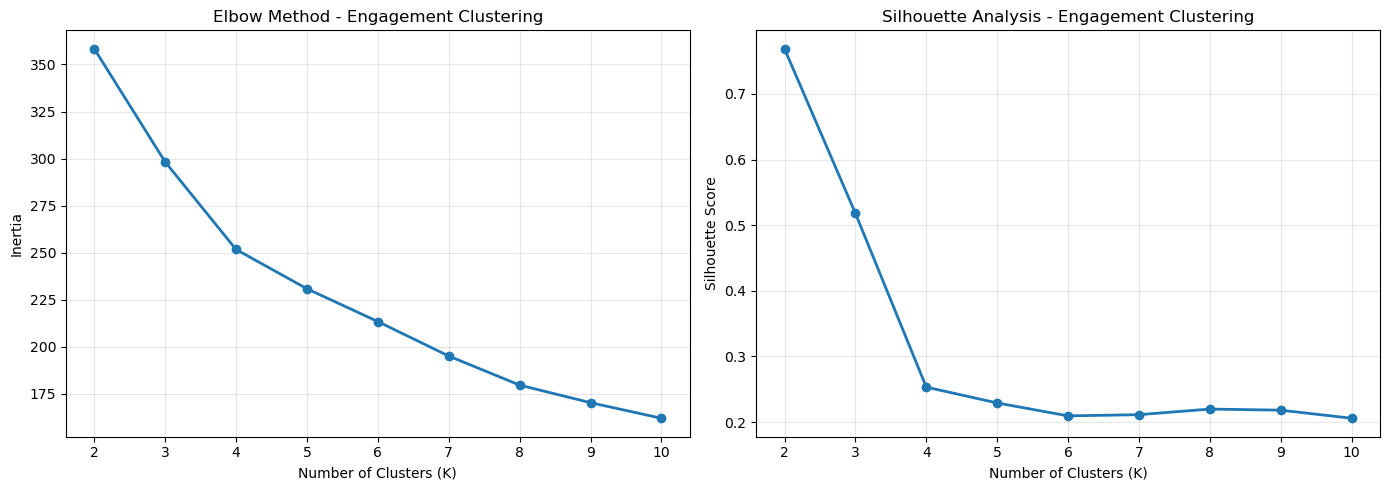

Best K based on Silhouette Score: 2
Highest Silhouette Score: 0.769


In [23]:
# Step 21: Elbow Method and Silhouette Analysis

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_engagement_scaled_df)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_engagement_scaled_df, labels)
    )

# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(
    k_values, inertias,
    marker="o", linewidth=2
)
axes[0].set_title("Elbow Method - Engagement Clustering")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

# Silhouette Score
axes[1].plot(
    k_values, silhouette_scores,
    marker="o", linewidth=2
)
axes[1].set_title("Silhouette Analysis - Engagement Clustering")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "engagement_cluster_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Report best K based on Silhouette Score
best_k = list(k_values)[
    silhouette_scores.index(max(silhouette_scores))
]

print("Best K based on Silhouette Score:", best_k)
print("Highest Silhouette Score:",
      round(max(silhouette_scores), 3))

## Step 22_ Final Engagement-Based Customer Segmentation



The Silhouette Analysis identified two clusters as the strongest solution, achieving a score of 0.769. Although the Elbow Method did not reveal a sharply defined turning point, the Silhouette Score provided clear support for selecting K=2.

I therefore selected two clusters for the final engagement segmentation model.

The next step is to assign customers to their respective clusters and examine their behavioral characteristics to determine whether the resulting segments are meaningful and actionable.

In [24]:
# Step 22: Final Engagement K-Means Model

engagement_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit model and assign engagement clusters
customer_df["Engagement_Cluster"] = (
    engagement_kmeans.fit_predict(X_engagement_scaled_df)
)

# Customer distribution
engagement_counts = (
    customer_df["Engagement_Cluster"]
    .value_counts()
    .sort_index()
)

engagement_percentages = (
    customer_df["Engagement_Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

engagement_summary = pd.DataFrame({
    "Customers": engagement_counts,
    "Percentage": engagement_percentages.round(2)
})

print("Engagement Cluster Distribution:")
display(engagement_summary)

# Final silhouette score
final_score = silhouette_score(
    X_engagement_scaled_df,
    customer_df["Engagement_Cluster"]
)

print("\nFinal Silhouette Score:", round(final_score, 3))

# Compare average engagement features
engagement_profile = (
    customer_df.groupby("Engagement_Cluster")[
        [
            "Avg_Browsing_Time",
            "Like_Rate",
            "Share_Rate",
            "Add_to_Cart_Rate"
        ]
    ]
    .mean()
    .round(3)
)

print("\nAverage Engagement Characteristics:")
display(engagement_profile)

Engagement Cluster Distribution:


C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,Customers,Percentage
Engagement_Cluster,,
0,405,50.94
1,390,49.06



Final Silhouette Score: 0.769

Average Engagement Characteristics:


,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Engagement_Cluster,,,,
0,21.249,0.721,0.676,0.791
1,13.169,0.410,0.328,0.538


### Engagement Segmentation — Key Findings

The engagement-based K-Means model identified two distinct customer segments with a Silhouette Score of 0.769.

#### Cluster 0 — High Engagement Customers (50.94%): These customers demonstrate longer browsing sessions, higher like and share rates, and more frequent add-to-cart activity.

#### Cluster 1 — Low Engagement Customers (49.06%): These customers show consistently lower levels of interaction across all four engagement metrics.

The results suggest that customer engagement can be meaningfully segmented into two groups within the selected feature space.

However, engagement does not necessarily translate into higher purchasing value. To investigate this distinction, I will develop a separate sales-based clustering model focused on customer purchasing behavior and revenue contribution.

The final analysis will compare both segmentation approaches to identify potential relationships between engagement and customer value.

## Step 23 _ Preparing Sales-Based Customer Segmentation

### Sales-Based Customer Segmentation: Feature Selection

Following the engagement analysis, I now focus on identifying customers based on their purchasing value and contribution to revenue.

For this analysis, I selected three customer-level features: Total Sales, Total Orders, and Average Order Value.

These features capture different aspects of purchasing behavior, including overall revenue contribution, purchase frequency, and average transaction value.

Before applying K-Means, I will examine the relationships between these features to assess potential redundancy and guide the final feature selection.

Sales dataset shape: (795, 3)

Missing values:
Total_Sales        0
Total_Orders       0
Avg_Order_Value    0
dtype: int64

Sales feature summary:


,Total_Sales,Total_Orders,Avg_Order_Value
count,795.0,795.00,795.0
mean,10091.16,64.51,156.37
std,2202.64,13.43,9.46
min,4249.0,29.00,124.75
25%,8554.5,55.00,150.01
50%,10017.0,64.00,156.29
75%,11552.5,74.00,162.93
max,17015.0,108.00,184.75


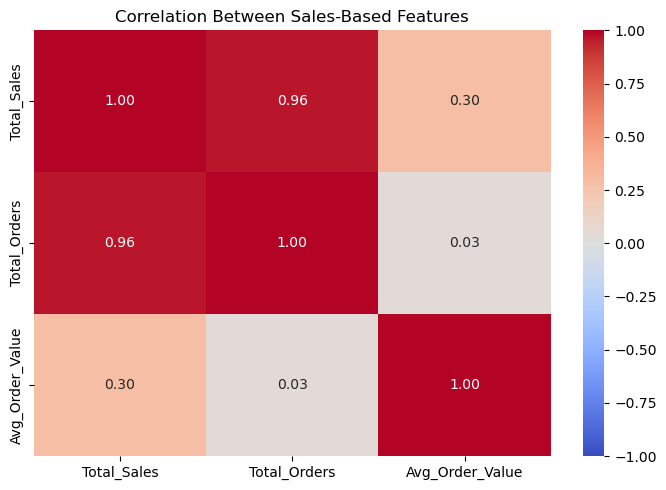

In [25]:
# Step 23: Sales-Based Feature Exploration

sales_features = [
    "Total_Sales",
    "Total_Orders",
    "Avg_Order_Value"
]

X_sales = customer_df[sales_features].copy()

print("Sales dataset shape:", X_sales.shape)

print("\nMissing values:")
print(X_sales.isna().sum())

print("\nSales feature summary:")
display(X_sales.describe().round(2))

# Correlation analysis
sales_corr = X_sales.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    sales_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sales-Based Features")
plt.tight_layout()
plt.show()

### Sales Feature Selection — Key Findings

The correlation analysis revealed a strong positive relationship between Total Sales and Total Orders (r = 0.96), suggesting substantial redundancy between these variables.

In contrast, Average Order Value showed a weaker correlation with Total Sales (r = 0.30) and almost no linear correlation with Total Orders (r = 0.03).

To reduce redundant weighting while maintaining a focus on customer revenue contribution, I selected Total Sales and Average Order Value as the two features for sales-based clustering.

Total Orders will be retained for customer profiling and business interpretation after clustering.

This approach allows the model to distinguish customers based on their overall purchasing value and average transaction size.

## Step 24_ Scaling Sales Features

In [26]:
# Step 24: Standardize Sales Features


sales_selected_features = [
    "Total_Sales",
    "Avg_Order_Value"
]

X_sales = customer_df[sales_selected_features].copy()

sales_scaler = StandardScaler()

X_sales_scaled = sales_scaler.fit_transform(X_sales)

X_sales_scaled_df = pd.DataFrame(
    X_sales_scaled,
    columns=sales_selected_features,
    index=X_sales.index
)

print("Scaled sales dataset shape:",
      X_sales_scaled_df.shape)

print("\nMean after scaling:")
print(X_sales_scaled_df.mean().round(2))

print("\nStandard deviation after scaling:")
print(X_sales_scaled_df.std(ddof=0).round(2))

display(X_sales_scaled_df.head())

Scaled sales dataset shape: (795, 2)

Mean after scaling:
Total_Sales       -0.0
Avg_Order_Value   -0.0
dtype: float64

Standard deviation after scaling:
Total_Sales        1.0
Avg_Order_Value    1.0
dtype: float64


,Total_Sales,Avg_Order_Value
0,-0.513870,-0.199766
1,-1.022670,1.889240
2,-1.064918,0.183259
3,-0.918184,-0.124675
4,-0.273553,-0.351564


## Step 25_ Finding the Optimal Number of Sales Clusters

### Determining the Optimal Number of Sales-Based Clusters

To determine the appropriate number of customer segments, I evaluate K-Means clustering using both the Elbow Method and Silhouette Analysis.

The Elbow Method examines how within-cluster variation decreases as the number of clusters increases, while the Silhouette Score evaluates how well customers are separated into distinct groups.

I compare the results of both methods to select a cluster count that balances statistical quality with meaningful business interpretation.

C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

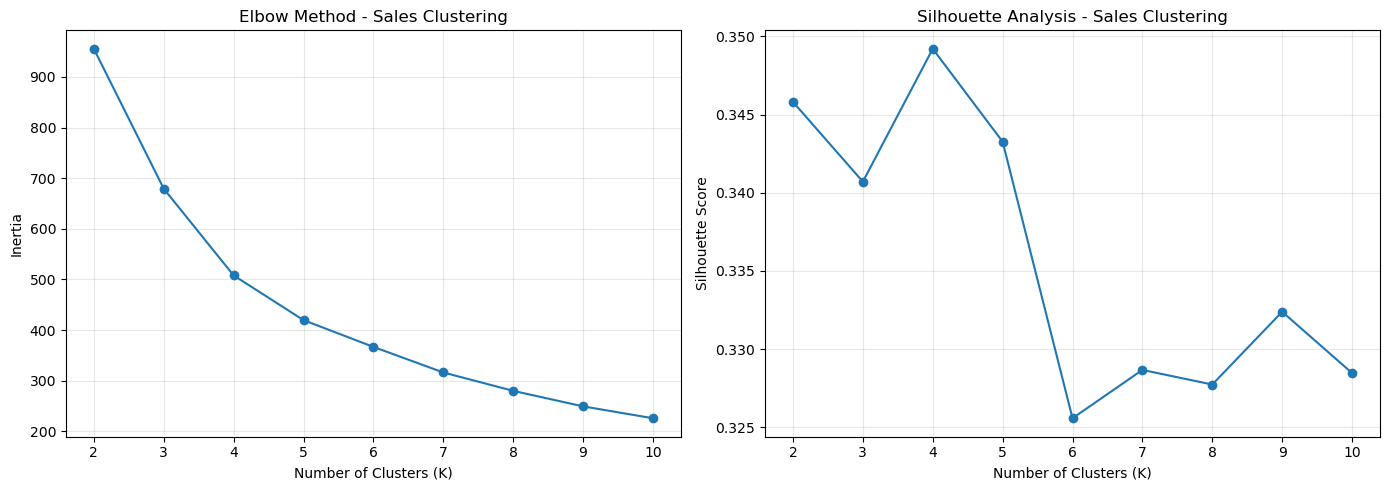

Best K based on Silhouette Score: 4
Highest Silhouette Score: 0.349


In [27]:
# Step 25: Elbow Method and Silhouette Analysis

k_values = range(2, 11)

sales_inertia = []
sales_silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sales_scaled_df)

    sales_inertia.append(model.inertia_)

    sales_silhouette_scores.append(
        silhouette_score(X_sales_scaled_df, labels)
    )

# Plot both evaluation methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    k_values, sales_inertia,
    marker="o"
)
axes[0].set_title("Elbow Method - Sales Clustering")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    k_values, sales_silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Analysis - Sales Clustering")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "sales_cluster_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

best_k_sales = list(k_values)[
    sales_silhouette_scores.index(
        max(sales_silhouette_scores)
    )
]

print("Best K based on Silhouette Score:", best_k_sales)
print(
    "Highest Silhouette Score:",
    round(max(sales_silhouette_scores), 3)
)

## Step 26_ Final Sales-Based K_Means Clustering



Based on the Elbow Method and Silhouette Analysis, I selected four clusters for the sales-based customer segmentation model.

Although the Silhouette Score of 0.349 indicates moderate cluster separation, four clusters provide a reasonable starting point for identifying different customer purchasing patterns.

I will now fit the final K-Means model and examine the distribution of customers across the four segments. The business relevance of these clusters will be evaluated using their purchasing characteristics.

In [28]:
# Step 26: Final Sales-Based K-Means Model

sales_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_df["Sales_Cluster"] = sales_kmeans.fit_predict(
    X_sales_scaled_df
)

# Customer distribution across sales clusters
sales_cluster_counts = (
    customer_df["Sales_Cluster"]
    .value_counts()
    .sort_index()
)

sales_cluster_percentages = (
    customer_df["Sales_Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

sales_cluster_summary = pd.DataFrame({
    "Customers": sales_cluster_counts,
    "Percentage": sales_cluster_percentages.round(2)
})

print("Sales Cluster Distribution:")
display(sales_cluster_summary)

print("\nFinal Sales Silhouette Score:")
print(round(
    silhouette_score(
        X_sales_scaled_df,
        customer_df["Sales_Cluster"]
    ), 3
))

Sales Cluster Distribution:


C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,Customers,Percentage
Sales_Cluster,,
0,230,28.93
1,168,21.13
2,161,20.25
3,236,29.69



Final Sales Silhouette Score:
0.349


## Step 27 — Sales-Based Customer Profiling

After identifying four sales-based customer clusters, I examine their purchasing characteristics to understand how the segments differ in business value.

I compare average total sales, order frequency, and average order value across the clusters. I also calculate each cluster’s contribution to total revenue.

This analysis helps identify high-value customers and provides a foundation for developing targeted customer retention and marketing strategies.

In [29]:
# Step 27: Sales-Based Customer Profiling

sales_profile = (
    customer_df.groupby("Sales_Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Avg_Total_Sales=("Total_Sales", "mean"),
        Avg_Total_Orders=("Total_Orders", "mean"),
        Avg_Order_Value=("Avg_Order_Value", "mean"),
        Total_Revenue=("Total_Sales", "sum")
    )
)

# Calculate revenue contribution
sales_profile["Revenue_Share_%"] = (
    sales_profile["Total_Revenue"]
    / sales_profile["Total_Revenue"].sum() * 100
)

print("Sales-Based Customer Profiles:")
display(sales_profile.round(2))

Sales-Based Customer Profiles:


,Customers,Avg_Total_Sales,Avg_Total_Orders,Avg_Order_Value,Total_Revenue,Revenue_Share_%
Sales_Cluster,,,,,,
0,230,10857.65,71.85,151.3,2497259.0,31.13
1,168,7784.85,53.48,145.76,1307854.0,16.3
2,161,13026.27,79.55,164.11,2097229.0,26.14
3,236,8983.6,54.94,163.59,2120130.0,26.43


## Step 28 — Visualizing Sales-Based Customer Segments

To better understand the business value of the identified customer segments, I visualize two key metrics: average customer spending and total revenue contribution.

These metrics provide complementary perspectives. Average customer spending identifies segments with higher individual purchasing value, while revenue contribution highlights the segments that generate the largest share of overall sales.

Together, these visualizations help translate the clustering results into actionable business insights.

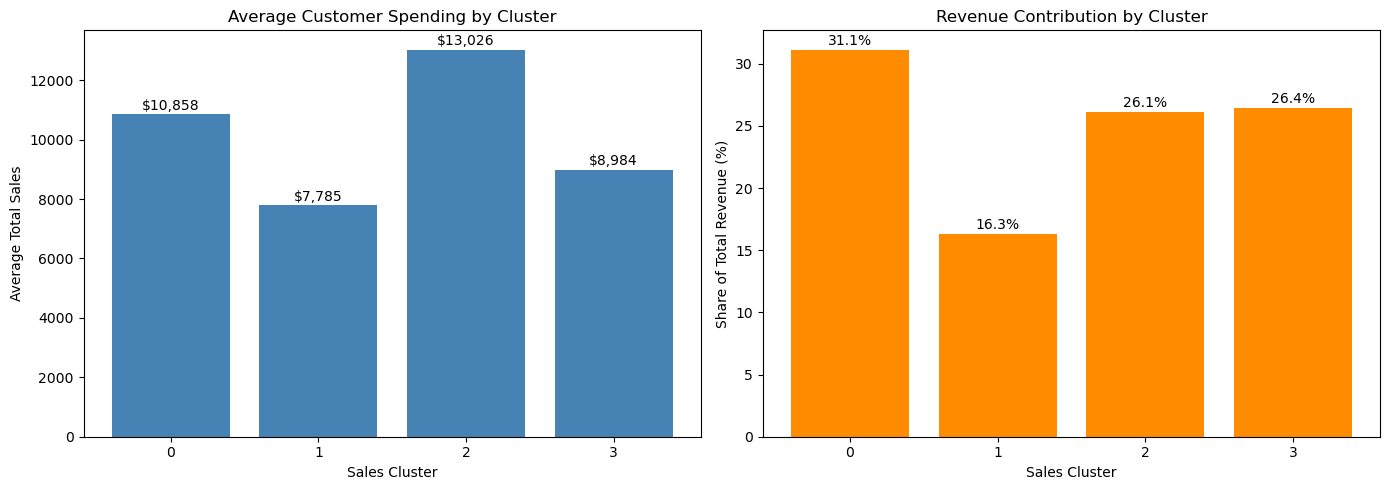

In [30]:
# Step 28: Visualize Sales-Based Customer Segments

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

clusters = sales_profile.index.astype(str)

# Average customer spending
axes[0].bar(
    clusters,
    sales_profile["Avg_Total_Sales"],
    color="steelblue"
)

axes[0].set_title("Average Customer Spending by Cluster")
axes[0].set_xlabel("Sales Cluster")
axes[0].set_ylabel("Average Total Sales")

for i, value in enumerate(sales_profile["Avg_Total_Sales"]):
    axes[0].text(
        i, value + 150,
        f"${value:,.0f}",
        ha="center"
    )

# Revenue contribution
axes[1].bar(
    clusters,
    sales_profile["Revenue_Share_%"],
    color="darkorange"
)

axes[1].set_title("Revenue Contribution by Cluster")
axes[1].set_xlabel("Sales Cluster")
axes[1].set_ylabel("Share of Total Revenue (%)")

for i, value in enumerate(sales_profile["Revenue_Share_%"]):
    axes[1].text(
        i, value + 0.4,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "sales_customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 29 — Business Interpretation of Sales-Based Customer Segments

I assign descriptive business labels to the four sales-based clusters based on their purchasing characteristics.

#### Cluster 0 represents frequent buyers who collectively contribute the largest share of total revenue.
#### Cluster 1 includes lower-value customers with relatively limited purchasing activity. 
#### Cluster 2 contains high-value customers with the highest average spending and order frequency, while 
#### Cluster 3 represents customers with relatively high average order values but fewer purchases.

These labels provide a practical interpretation of the clustering results and help identify opportunities for customer retention, loyalty programs, and targeted marketing.

In [31]:
# Step 29: Assign Business Labels to Sales Clusters

sales_segment_labels = {
    0: "Frequent Buyers",
    1: "Low-Value Customers",
    2: "High-Value Customers",
    3: "High-Ticket Buyers"
}

customer_df["Sales_Segment"] = (
    customer_df["Sales_Cluster"]
    .map(sales_segment_labels)
)

# Add business labels to cluster profiles
sales_profile_labeled = sales_profile.copy()

sales_profile_labeled["Segment"] = (
    sales_profile_labeled.index.map(
        sales_segment_labels
    )
)

# Reorder columns for readability
sales_profile_labeled = sales_profile_labeled[
    ["Segment", "Customers", "Avg_Total_Sales",
     "Avg_Total_Orders", "Avg_Order_Value",
     "Total_Revenue", "Revenue_Share_%"]
]

print("Final Sales-Based Customer Segments:")
display(sales_profile_labeled.round(2))

Final Sales-Based Customer Segments:


,Segment,Customers,Avg_Total_Sales,Avg_Total_Orders,Avg_Order_Value,Total_Revenue,Revenue_Share_%
Sales_Cluster,,,,,,,
0,Frequent Buyers,230,10857.65,71.85,151.3,2497259.0,31.13
1,Low-Value Customers,168,7784.85,53.48,145.76,1307854.0,16.3
2,High-Value Customers,161,13026.27,79.55,164.11,2097229.0,26.14
3,High-Ticket Buyers,236,8983.6,54.94,163.59,2120130.0,26.43


## Step 30 — Relationship Between Sales and Customer Engagement

After independently identifying customer segments based on purchasing behavior and engagement activity, I examine how these two segmentation approaches relate to each other.

The objective is to determine whether customers with higher purchasing value also demonstrate higher engagement levels.

I use a cross-tabulation to compare sales-based and engagement-based clusters, followed by a heatmap to visualize the distribution of customers across both segmentation models.

This analysis helps connect customer engagement patterns with business value without introducing an additional clustering model.

Customer Distribution by Sales and Engagement:


Engagement_Segment,High Engagement,Low Engagement
Sales_Segment,,
Frequent Buyers,103,127
High-Ticket Buyers,138,98
High-Value Customers,92,69
Low-Value Customers,72,96



Engagement Distribution Within Each Sales Segment (%):


Engagement_Segment,High Engagement,Low Engagement
Sales_Segment,,
Frequent Buyers,44.78,55.22
High-Ticket Buyers,58.47,41.53
High-Value Customers,57.14,42.86
Low-Value Customers,42.86,57.14


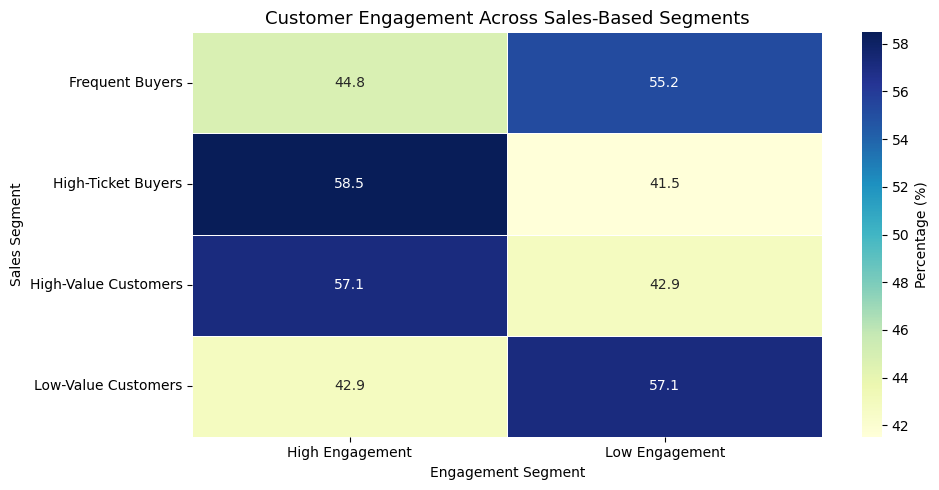

In [32]:
# Step 30: Compare Sales and Engagement Segments


# Assign engagement labels based on previous cluster profiles
engagement_labels = {
    0: "High Engagement",
    1: "Low Engagement"
}

customer_df["Engagement_Segment"] = (
    customer_df["Engagement_Cluster"]
    .map(engagement_labels)
)

# Cross-tabulation: customer counts
segment_comparison = pd.crosstab(
    customer_df["Sales_Segment"],
    customer_df["Engagement_Segment"]
)

print("Customer Distribution by Sales and Engagement:")
display(segment_comparison)

# Row percentages
segment_percentages = pd.crosstab(
    customer_df["Sales_Segment"],
    customer_df["Engagement_Segment"],
    normalize="index"
) * 100

print("\nEngagement Distribution Within Each Sales Segment (%):")
display(segment_percentages.round(2))

# Visualize percentage distribution
plt.figure(figsize=(10, 5))

sns.heatmap(
    segment_percentages,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title(
    "Customer Engagement Across Sales-Based Segments",
    fontsize=13
)
plt.xlabel("Engagement Segment")
plt.ylabel("Sales Segment")
plt.tight_layout()

plt.savefig(
    "sales_engagement_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 31 — Business Insights and Recommendations

The combined sales and engagement segmentation provides several actionable insights into customer purchasing behavior.

### 1. High-Value Customers — Retention Strategy

High-value customers demonstrate strong purchasing activity, with 57.14% belonging to the high-engagement segment.

I recommend prioritizing customer retention through personalized loyalty programs, exclusive offers, and targeted communication.

### 2. High-Ticket Buyers — Premium Product Strategy

Approximately 58.47% of high-ticket buyers demonstrate high engagement.

These customers may be suitable for premium product recommendations, personalized cross-selling, and carefully targeted upselling campaigns.

### 3. Frequent Buyers — Engagement Opportunities

Although frequent buyers make relatively frequent purchases, 55.22% belong to the low-engagement segment.

This suggests an opportunity to explore whether personalized recommendations and improved digital experiences could encourage greater engagement without disrupting their existing purchasing behavior.

### 4. Low-Value Customers — Growth Opportunities

Among low-value customers, 57.14% demonstrate low engagement.

I recommend testing targeted promotions, product discovery improvements, and personalized marketing campaigns to evaluate whether these strategies can improve engagement and purchasing activity.

### Overall Business Implication

The results suggest that purchasing value and customer engagement capture different dimensions of customer behavior.

By combining both segmentation approaches, businesses can develop more targeted strategies for customer retention, revenue growth, and marketing resource allocation.

These recommendations represent potential strategies rather than experimentally validated outcomes.

## Step 32 — Limitations and Future Improvements

Although the clustering analysis provides useful insights into customer purchasing behavior and engagement, several limitations should be considered when interpreting the results.

### 1. Clustering Performance

The engagement-based model achieved a Silhouette Score of 0.769, indicating strong separation between its two customer segments.

In comparison, the sales-based model achieved a Silhouette Score of 0.349 with four clusters, suggesting weaker separation and some potential overlap between customer groups.

Therefore, the sales segments should be interpreted as exploratory customer profiles rather than perfectly distinct categories.

### 2. Feature Correlation

The correlation analysis revealed strong relationships between several features.

For example, Total Sales and Total Orders showed a correlation of approximately 0.96, while engagement features demonstrated correlations ranging from approximately 0.89 to 0.94.

These relationships may cause certain behavioral dimensions to receive greater influence in distance-based clustering.

### 3. Methodological Limitations

K-Means assumes relatively compact clusters and relies on Euclidean distance. As a result, its performance may be limited when customer behavior follows more complex or overlapping patterns.

Additionally, the analysis is descriptive and does not establish causal relationships between customer engagement and purchasing behavior.

### 4. Future Improvements

Future research could explore alternative clustering algorithms, such as Hierarchical Clustering or DBSCAN, to evaluate whether different methods identify more meaningful customer segments.

Additional customer information, including purchase recency, customer tenure, and product preferences, could further improve segmentation if such data becomes available.

Finally, the proposed marketing strategies could be evaluated through A/B testing to determine whether they improve customer engagement, retention, or revenue.

### Final Reflection

Despite these limitations, I believe the two-dimensional segmentation approach provides a useful foundation for understanding customer behavior.

By analyzing sales performance and engagement separately, I was able to identify different customer profiles and translate the findings into potential business strategies.

# Step 33 — Final Conclusion

### Project Overview

In this project, I applied K-Means clustering to analyze customer purchasing behavior and engagement using an e-commerce dataset containing 795 customers.

My primary objective was to identify meaningful customer segments that could support data-driven marketing decisions, customer retention, and revenue growth.

### Modeling Approach

I initially developed a clustering model using both purchasing and engagement-related features. However, the results revealed that the identified clusters were primarily differentiated by engagement rather than purchasing value.

Based on this finding, I refined my analytical approach by developing two separate clustering models:

#### * Engagement-Based Segmentation: Using browsing time, like rate, share rate, and add-to-cart rate.
#### * Sales-Based Segmentation: Using total sales and average order value.

I applied feature standardization and evaluated different numbers of clusters using the Elbow Method and Silhouette Analysis.

### Key Findings

### 1. Engagement-Based Segmentation

The engagement model identified two customer groups with a Silhouette Score of 0.769, indicating strong cluster separation.

The results distinguished customers with high engagement from those with relatively low engagement.

### 2. Sales-Based Segmentation

The sales model identified four customer groups with a Silhouette Score of 0.349:

* High-Value Customers
* High-Ticket Buyers
* Frequent Buyers
* Low-Value Customers

These segments demonstrated different purchasing patterns, average spending levels, and contributions to total revenue.

### 3. Combined Sales and Engagement Analysis

By combining the two segmentation approaches, I identified additional patterns that would not have been visible through sales or engagement analysis alone.

For example, 58.47% of High-Ticket Buyers and 57.14% of High-Value Customers belonged to the high-engagement segment.

In contrast, 55.22% of Frequent Buyers belonged to the low-engagement segment.

These findings suggest that purchasing behavior and customer engagement provide complementary perspectives on customer characteristics.

### Business Value

The analysis provides a foundation for developing more targeted business strategies, including:

* Personalized marketing and product recommendations
* Customer retention and loyalty initiatives
* Premium product targeting and cross-selling opportunities
* Identifying opportunities to improve customer engagement

These strategies should be tested before their effectiveness can be established.

### Final Takeaway

This project demonstrated that customer segmentation is not simply about identifying clusters, but about understanding whether those clusters answer meaningful business questions.

One of the most important lessons I learned was the value of revisiting the analytical approach when initial results did not fully align with the business objective.

By separating sales performance from engagement behavior and then combining the findings, I developed a more interpretable framework for understanding customer differences and identifying potential business opportunities.

Although the results remain exploratory, they provide a practical foundation for future customer analytics and data-driven decision-making.